In [1]:
# 1. Import necessary libraries from Qiskit
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram


In [5]:
# Initialize the standard simulator
simulator = AerSimulator()

In [6]:

# Step 1: Create a single-qubit quantum circuit with 1 classical bit
qc_bias_0 = QuantumCircuit(1, 1)

# Step 2 & 3: Apply single-qubit gates to bias towards |0⟩
qc_bias_0.h(0)  # Creates equal superposition
qc_bias_0.t(0)  # Applies a pi/4 phase shift
qc_bias_0.h(0)  # Constructive interference for |0⟩, destructive for |1⟩

# Step 4: Measure the qubit into the classical bit
qc_bias_0.measure(0, 0)

# Step 5: Execute the circuit for 100 shots
result_0 = simulator.run(qc_bias_0, shots=100).result()

# Step 6: Extract the outcome counts
counts_0 = result_0.get_counts()
print("Circuit 1 (Biased towards 0) Counts:", counts_0)



Circuit 1 (Biased towards 0) Counts: {'0': 92, '1': 8}


In [7]:
# Step 1: Create another single-qubit quantum circuit
qc_bias_1 = QuantumCircuit(1, 1)

# Step 2 & 3: Invert the state beforehand or post-interference to bias towards |1⟩
qc_bias_1.h(0)
qc_bias_1.t(0)
qc_bias_1.h(0)
qc_bias_1.x(0)  # NOT gate flips the 85% probability onto |1⟩

# Step 4: Measure the qubit
qc_bias_1.measure(0, 0)

# Step 5: Execute for 100 shots
result_1 = simulator.run(qc_bias_1, shots=100).result()

# Step 6: Extract the outcome counts
counts_1 = result_1.get_counts()
print("Circuit 2 (Biased towards 1) Counts:", counts_1)

Circuit 2 (Biased towards 1) Counts: {'1': 95, '0': 5}


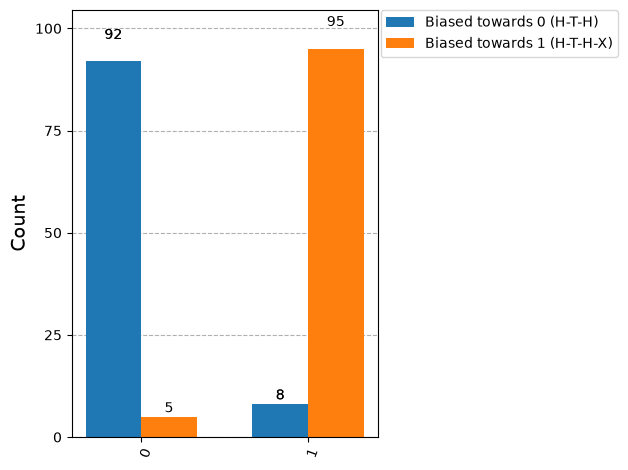

In [8]:
plot_histogram([counts_0, counts_1], legend=['Biased towards 0 (H-T-H)', 'Biased towards 1 (H-T-H-X)'])
